# Demostracion de ciencia de datos internacional
Este notebook presenta el ciclo completo aprobado: EDA, caracteristicas temporales, particion, baseline, Random Forest, pruebas estadisticas, validacion por fuente, interpretacion y decision. Lee artefactos ya calculados y no repite el entrenamiento pesado.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
MODEL_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'modeling'
VALIDATION_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'validation'
FEATURES_PATH = PROJECT_ROOT / 'data' / '04_model_output' / 'features' / 'tsi_daily_features.parquet'
RESULTS_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'results'
features = pd.read_parquet(FEATURES_PATH)
metrics = pd.read_csv(MODEL_DIR / 'metricas_modelos.csv')
tests = pd.read_csv(MODEL_DIR / 'pruebas_modelos_vs_baseline.csv')
predictions = pd.read_csv(MODEL_DIR / 'predicciones_prueba.csv', parse_dates=['fecha'])
by_source = pd.read_csv(VALIDATION_DIR / 'metricas_por_fuente.csv')
bootstrap = pd.read_csv(VALIDATION_DIR / 'intervalo_bootstrap_mejora.csv')
summary = json.loads((RESULTS_DIR / 'resumen_experimento_internacional.json').read_text(encoding='utf-8'))
print('Artefactos de ciencia de datos cargados sin reentrenar modelos.')

Artefactos de ciencia de datos cargados sin reentrenar modelos.


,etapa,resultado
0,EDA modelable,"9,742 filas con objetivo y caracteristicas"
1,Fuentes,5 fuentes internacionales
2,Ventana temporal,2001-01-04 a 2024-10-17
3,Predictores,"rezagos, delta, medias moviles, variabilidad y..."


,fuente,filas,media_tsi,objetivo_medio
0,istanbul_traffic_index,3329,54.157208,54.175932
1,madrid_traffic_points,28,98.609430,98.610336
2,metr_la,116,76.710683,76.638055
3,pems_bay,178,73.548515,73.552044
4,sao_paulo_cet,6091,94.244303,94.243048


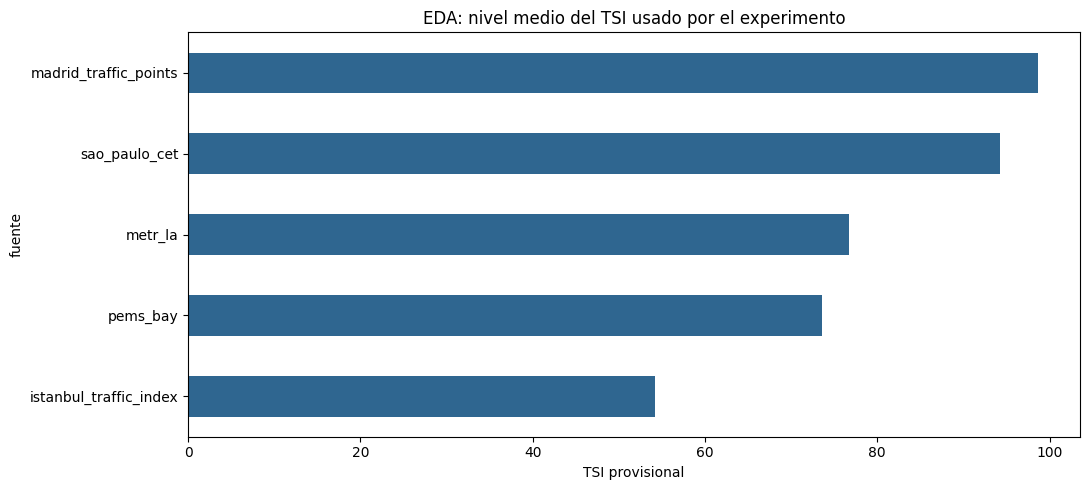

In [2]:
eda_summary = pd.DataFrame([
    {'etapa': 'EDA modelable', 'resultado': f"{len(features):,} filas con objetivo y caracteristicas"},
    {'etapa': 'Fuentes', 'resultado': f"{features['fuente'].nunique()} fuentes internacionales"},
    {'etapa': 'Ventana temporal', 'resultado': f"{features['fecha'].min().date()} a {features['fecha'].max().date()}"},
    {'etapa': 'Predictores', 'resultado': 'rezagos, delta, medias moviles, variabilidad y calendario'},
])
display(eda_summary)
display(features.groupby('fuente', as_index=False).agg(filas=('fecha', 'size'), media_tsi=('tsi_provisional_media', 'mean'), objetivo_medio=('objetivo_tsi_siguiente', 'mean')))
fig, ax = plt.subplots(figsize=(11, 5))
features.groupby('fuente')['tsi_provisional_media'].mean().sort_values().plot.barh(ax=ax, color='#2f6690')
ax.set_title('EDA: nivel medio del TSI usado por el experimento')
ax.set_xlabel('TSI provisional')
plt.tight_layout()
plt.show()

In [3]:
partition = pd.DataFrame([
    {'particion': 'train', 'filas': 5827},
    {'particion': 'validation', 'filas': 1944},
    {'particion': 'test', 'filas': 1946},
])
display(partition)
feature_view = features[['fuente', 'fecha', 'tsi_provisional_media', 'tsi_lag_1', 'tsi_lag_7', 'delta_1', 'media_movil_3', 'media_movil_7', 'desviacion_movil_7', 'objetivo_tsi_siguiente']].head()
display(feature_view)
print('Control: los rezagos y ventanas usan informacion anterior al objetivo.')

,particion,filas
0,train,5827
1,validation,1944
2,test,1946


,fuente,fecha,tsi_provisional_media,tsi_lag_1,tsi_lag_7,delta_1,media_movil_3,media_movil_7,desviacion_movil_7,objetivo_tsi_siguiente
0,istanbul_traffic_index,2015-08-11,35.697024,61.116274,NaN,-25.419250,31.903981,NaN,NaN,50.927190
1,istanbul_traffic_index,2015-08-12,50.927190,35.697024,NaN,15.230166,33.168329,33.168329,29.294263,52.911582
2,istanbul_traffic_index,2015-08-13,52.911582,50.927190,NaN,1.984392,49.246830,37.608044,25.513660,46.497098
3,istanbul_traffic_index,2015-08-14,46.497098,52.911582,NaN,-6.414484,46.511932,40.668752,23.131143,60.407493
4,istanbul_traffic_index,2015-08-15,60.407493,46.497098,NaN,13.910395,50.111957,41.640143,20.825500,83.706542


Control: los rezagos y ventanas usan informacion anterior al objetivo.


,modelo,mae,rmse,r2
0,random_forest,2.511087,5.274513,0.947871
1,ridge,3.514525,6.338738,0.924712
2,baseline_persistencia,5.302138,9.950087,0.814488


,modelo,mejora_mae_vs_baseline,t_pareada_p_valor,wilcoxon_p_valor
0,ridge,1.787612,9.673231e-31,1.372203e-21
1,random_forest,2.791051,2.731364e-64,1.632495e-113


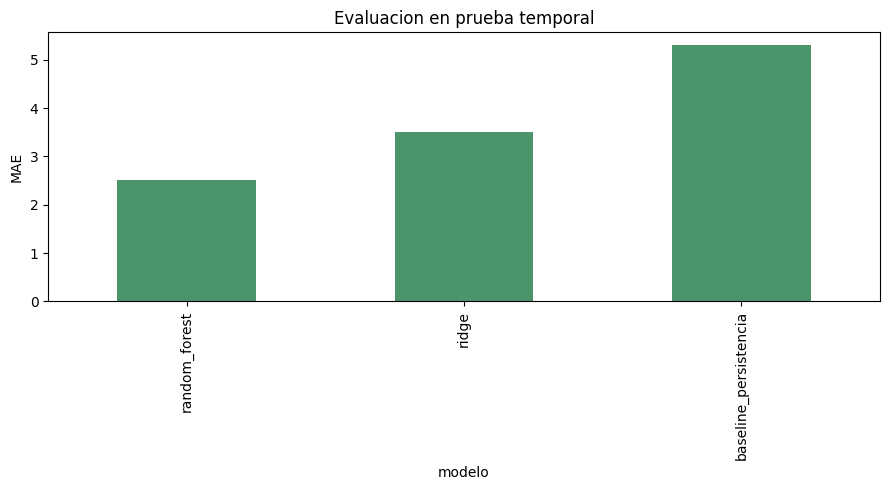

In [4]:
display(metrics.sort_values('mae'))
display(tests)
model_comparison = metrics[['modelo', 'mae', 'rmse', 'r2']].sort_values('mae')
ax = model_comparison.plot.bar(x='modelo', y='mae', figsize=(9, 5), legend=False, color='#4c956c')
ax.set_title('Evaluacion en prueba temporal')
ax.set_ylabel('MAE')
plt.tight_layout()
plt.show()

In [5]:
display(pd.DataFrame([
    {'prueba': 't pareada', 'modelo': 'random_forest', 'p_valor': tests.loc[tests['modelo'] == 'random_forest', 't_pareada_p_valor'].iloc[0]},
    {'prueba': 'Wilcoxon', 'modelo': 'random_forest', 'p_valor': tests.loc[tests['modelo'] == 'random_forest', 'wilcoxon_p_valor'].iloc[0]},
    {'prueba': 'bootstrap IC95 inferior', 'modelo': 'random_forest', 'p_valor': bootstrap['ic95_inferior'].iloc[0]},
    {'prueba': 'bootstrap IC95 superior', 'modelo': 'random_forest', 'p_valor': bootstrap['ic95_superior'].iloc[0]},
]))
display(by_source[['fuente_original', 'filas_prueba', 'mae_baseline', 'mae_random_forest', 'mejora_mae', 'mejora_relativa_pct']])

,prueba,modelo,p_valor
0,t pareada,random_forest,2.731364e-64
1,Wilcoxon,random_forest,1.632495e-113
2,bootstrap IC95 inferior,random_forest,2.481661e+00
3,bootstrap IC95 superior,random_forest,3.089033e+00


,fuente_original,filas_prueba,mae_baseline,mae_random_forest,mejora_mae,mejora_relativa_pct
0,istanbul_traffic_index,665.0,12.113811,5.370551,6.743260,55.665883
1,madrid_traffic_points,5.0,0.248895,0.946630,-0.697736,-280.333651
2,metr_la,23.0,12.689391,10.807494,1.881897,14.830472
3,pems_bay,35.0,3.112371,0.624970,2.487401,79.919814
4,sao_paulo_cet,1218.0,1.527293,0.853842,0.673451,44.094419


,fuente_original,sesgo,error_mediano,error_p95
0,istanbul_traffic_index,-1.029447,3.369512,18.023493
1,madrid_traffic_points,0.946630,0.843895,1.390174
2,metr_la,-0.763730,5.528083,31.726503
3,pems_bay,0.086070,0.295028,1.794381
4,sao_paulo_cet,0.202997,0.565381,2.752055


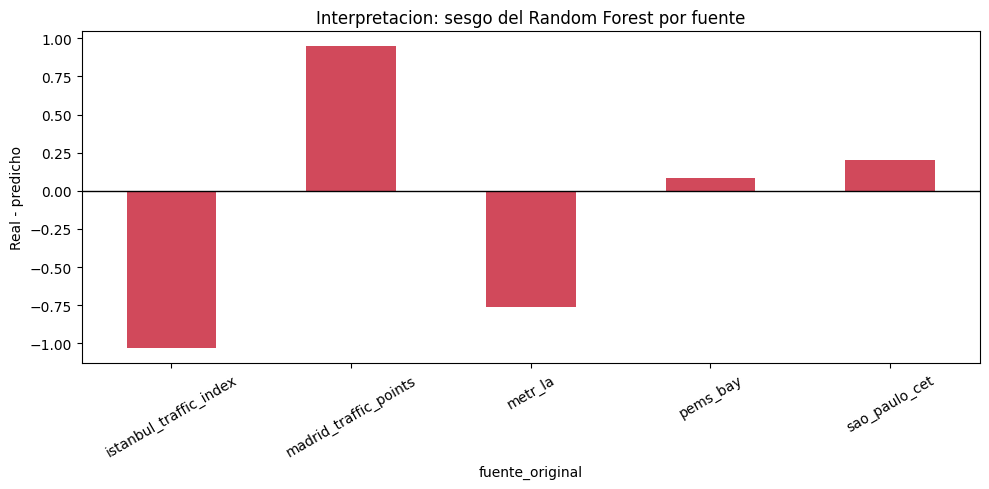

In [6]:
predictions['error_random_forest'] = predictions['real'] - predictions['random_forest']
predictions['abs_random_forest'] = predictions['error_random_forest'].abs()
interpretation = predictions.groupby('fuente_original', as_index=False).agg(
    sesgo=('error_random_forest', 'mean'),
    error_mediano=('abs_random_forest', 'median'),
    error_p95=('abs_random_forest', lambda values: values.quantile(0.95)),
)
display(interpretation)
fig, ax = plt.subplots(figsize=(10, 5))
interpretation.plot.bar(x='fuente_original', y='sesgo', ax=ax, legend=False, color='#d1495b', rot=30)
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Interpretacion: sesgo del Random Forest por fuente')
ax.set_ylabel('Real - predicho')
plt.tight_layout()
plt.show()

In [7]:
decision = pd.DataFrame([
    {'elemento': 'modelo_candidato', 'resultado': summary['modelo_candidato']},
    {'elemento': 'MAE_modelo', 'resultado': summary['mae_prueba_modelo_candidato']},
    {'elemento': 'MAE_baseline', 'resultado': summary['mae_prueba_baseline']},
    {'elemento': 'fuentes_con_mejora', 'resultado': f"{summary['fuentes_con_mejora']}/{summary['fuentes_evaluadas']}"},
    {'elemento': 'excepciones', 'resultado': ', '.join(summary['excepciones'])},
    {'elemento': 'estado', 'resultado': summary['estado']},
])
display(decision)

,elemento,resultado
0,modelo_candidato,random_forest
1,MAE_modelo,2.511087
2,MAE_baseline,5.302138
3,fuentes_con_mejora,4/5
4,excepciones,madrid_traffic_points
5,estado,candidato_internacional_no_final


## Decision demostrada
Random Forest es el candidato internacional para pronosticar el TSI provisional del siguiente dia y supera la persistencia en el promedio. La evidencia por fuente es mixta porque Madrid tiene solo cinco filas de prueba y no mejora al baseline. Este notebook demuestra el experimento aprobado.